In [1]:
from pydantic import BaseModel
from langgraph.graph import StateGraph,START,END

In [2]:
class GreetState(BaseModel):
    message:str=""

In [28]:
graph=StateGraph(GreetState)

#### Nodes - Python Functions

In [29]:
def Greet(state:GreetState):
    state.message=f"{state.message} ! Hello ALL!"
    return state

def UpperCase(state:GreetState):
    state.message=state.message.upper()
    return state

In [30]:
graph.add_node("greet",Greet)
graph.add_node("uppercase",UpperCase)

In [31]:
graph.add_edge(START,"greet")
graph.add_edge("greet","uppercase")
graph.add_edge("uppercase",END)

In [32]:
finalGraph=graph.compile()

In [33]:
res=finalGraph.invoke({"message":"I love langgraph!"})

In [34]:
res

{'message': 'I LOVE LANGGRAPH! ! HELLO ALL!'}

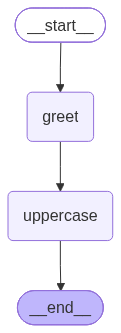

In [35]:
from IPython.display import Image
Image(finalGraph.get_graph().draw_mermaid_png())